In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving titanic_cleaned_sample.csv to titanic_cleaned_sample.csv


In [3]:
import io

file_name = list(uploaded.keys())[0]

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (6, 11)

Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Embarked']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  6 non-null      int64  
 1   Survived     6 non-null      int64  
 2   Pclass       6 non-null      int64  
 3   Name         6 non-null      object 
 4   Sex          6 non-null      object 
 5   Age          6 non-null      float64
 6   SibSp        6 non-null      int64  
 7   Parch        6 non-null      int64  
 8   Ticket       6 non-null      object 
 9   Fare         6 non-null      float64
 10  Embarked     6 non-null      object 
dtypes: float64(2), int64(5), object(4)
memory usage: 660.0+ bytes


In [6]:
# Statistical Analysis

print("STATISTICAL SUMMARY")
display(df.describe())

print("\nMean Values:")
display(df.mean(numeric_only=True))

print("\nMedian Values:")
display(df.median(numeric_only=True))

print("\nMode Values:")
display(df.mode().head(1))

STATISTICAL SUMMARY


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,6.000000,6.000000,6.000000,6.000000,6.000000,6.0,6.000000
mean,3.500000,0.500000,2.333333,31.833333,0.500000,0.0,26.011100
std,1.870829,0.547723,1.032796,6.306082,0.547723,0.0,28.611775
min,1.000000,0.000000,1.000000,22.000000,0.000000,0.0,7.250000
25%,2.250000,0.000000,1.500000,28.250000,0.000000,0.0,7.956250
50%,3.500000,0.500000,3.000000,35.000000,0.500000,0.0,8.254150
75%,4.750000,1.000000,3.000000,35.000000,1.000000,0.0,41.939575
max,6.000000,1.000000,3.000000,38.000000,1.000000,0.0,71.283300



Mean Values:


,0
PassengerId,3.500000
Survived,0.500000
Pclass,2.333333
Age,31.833333
SibSp,0.500000
Parch,0.000000
Fare,26.011100



Median Values:


,0
PassengerId,3.50000
Survived,0.50000
Pclass,3.00000
Age,35.00000
SibSp,0.50000
Parch,0.00000
Fare,8.25415



Mode Values:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0.0,3.0,"Allen, Mr. William Henry",female,35.0,0.0,0.0,113803,7.25,S


In [7]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

Total Missing Values:
0


In [8]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [9]:
# Outlier Detection using IQR

numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"\nColumn: {col}")
    print("Number of outliers:", len(outliers))


Column: PassengerId
Number of outliers: 0

Column: Survived
Number of outliers: 0

Column: Pclass
Number of outliers: 0

Column: Age
Number of outliers: 0

Column: SibSp
Number of outliers: 0

Column: Parch
Number of outliers: 0

Column: Fare
Number of outliers: 0


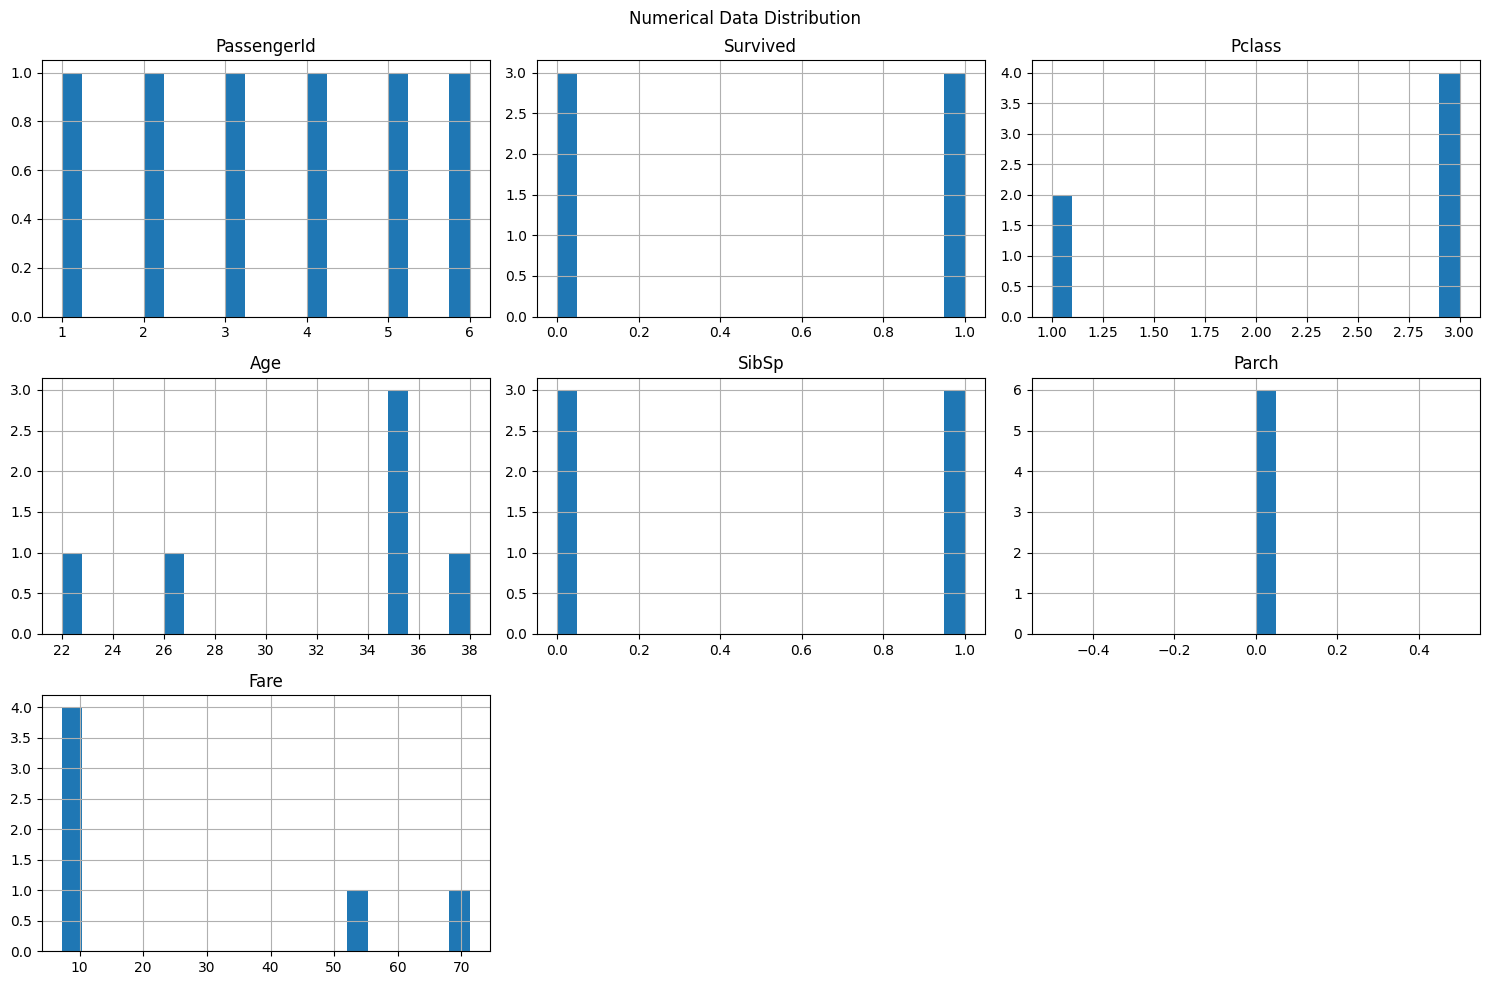

In [13]:
df.hist(figsize=(15, 10), bins=20)
plt.suptitle("Numerical Data Distribution")
plt.tight_layout()
plt.show()

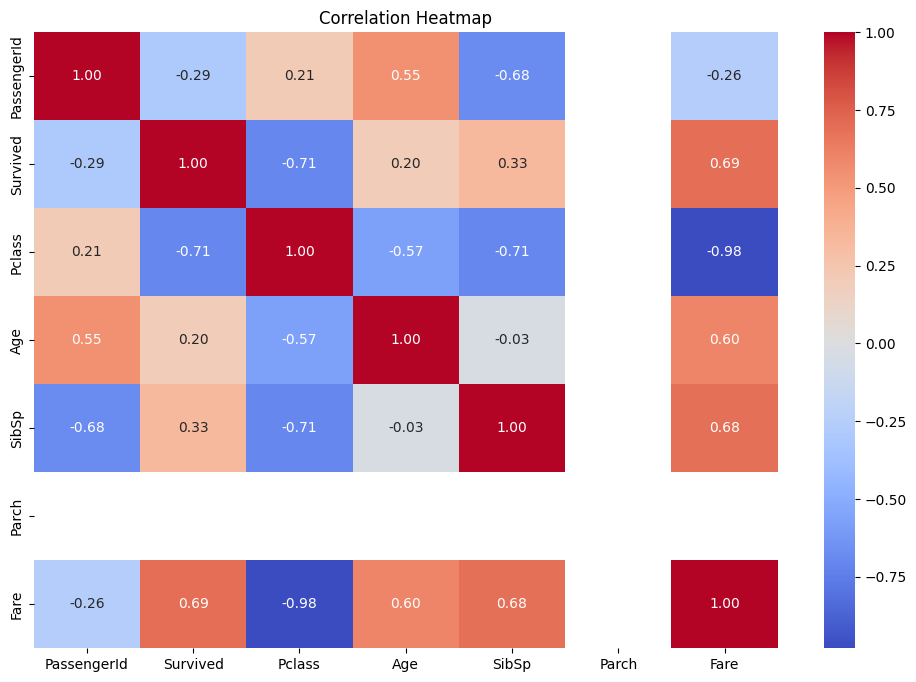

In [11]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

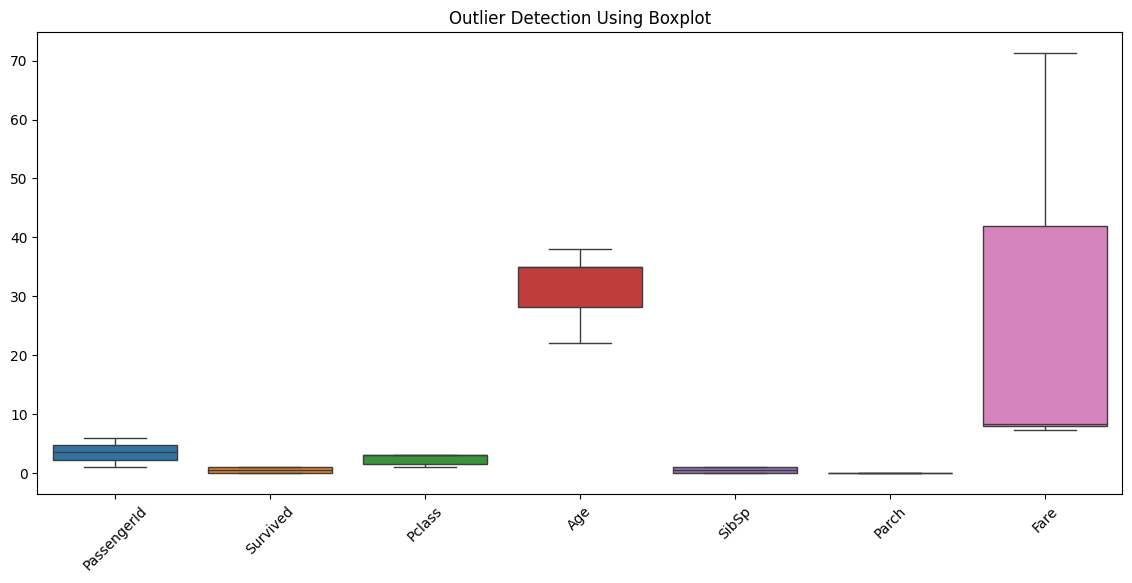

In [12]:
plt.figure(figsize=(14, 6))

sns.boxplot(data=df.select_dtypes(include=np.number))

plt.title("Outlier Detection Using Boxplot")
plt.xticks(rotation=45)
plt.show()

In [14]:
# Dataset Insights

print("1. Total Records:", len(df))

print("2. Total Columns:", len(df.columns))

print("3. Missing Values:", df.isnull().sum().sum())

print("4. Duplicate Records:", df.duplicated().sum())

print("5. Numerical Columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nTop Categories in Categorical Columns:")

for col in df.select_dtypes(include="object").columns:
    print("\n", col)
    print(df[col].value_counts().head(5))

1. Total Records: 6
2. Total Columns: 11
3. Missing Values: 0
4. Duplicate Records: 0
5. Numerical Columns:
['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

Top Categories in Categorical Columns:

 Name
Name
Braund, Mr. Owen Harris                                1
Cumings, Mrs. John Bradley (Florence Briggs Thayer)    1
Heikkinen, Miss. Laina                                 1
Futrelle, Mrs. Jacques Heath (Lily May Peel)           1
Allen, Mr. William Henry                               1
Name: count, dtype: int64

 Sex
Sex
male      3
female    3
Name: count, dtype: int64

 Ticket
Ticket
A/5 21171           1
PC 17599            1
STON/O2. 3101282    1
113803              1
373450              1
Name: count, dtype: int64

 Embarked
Embarked
S    4
C    1
Q    1
Name: count, dtype: int64


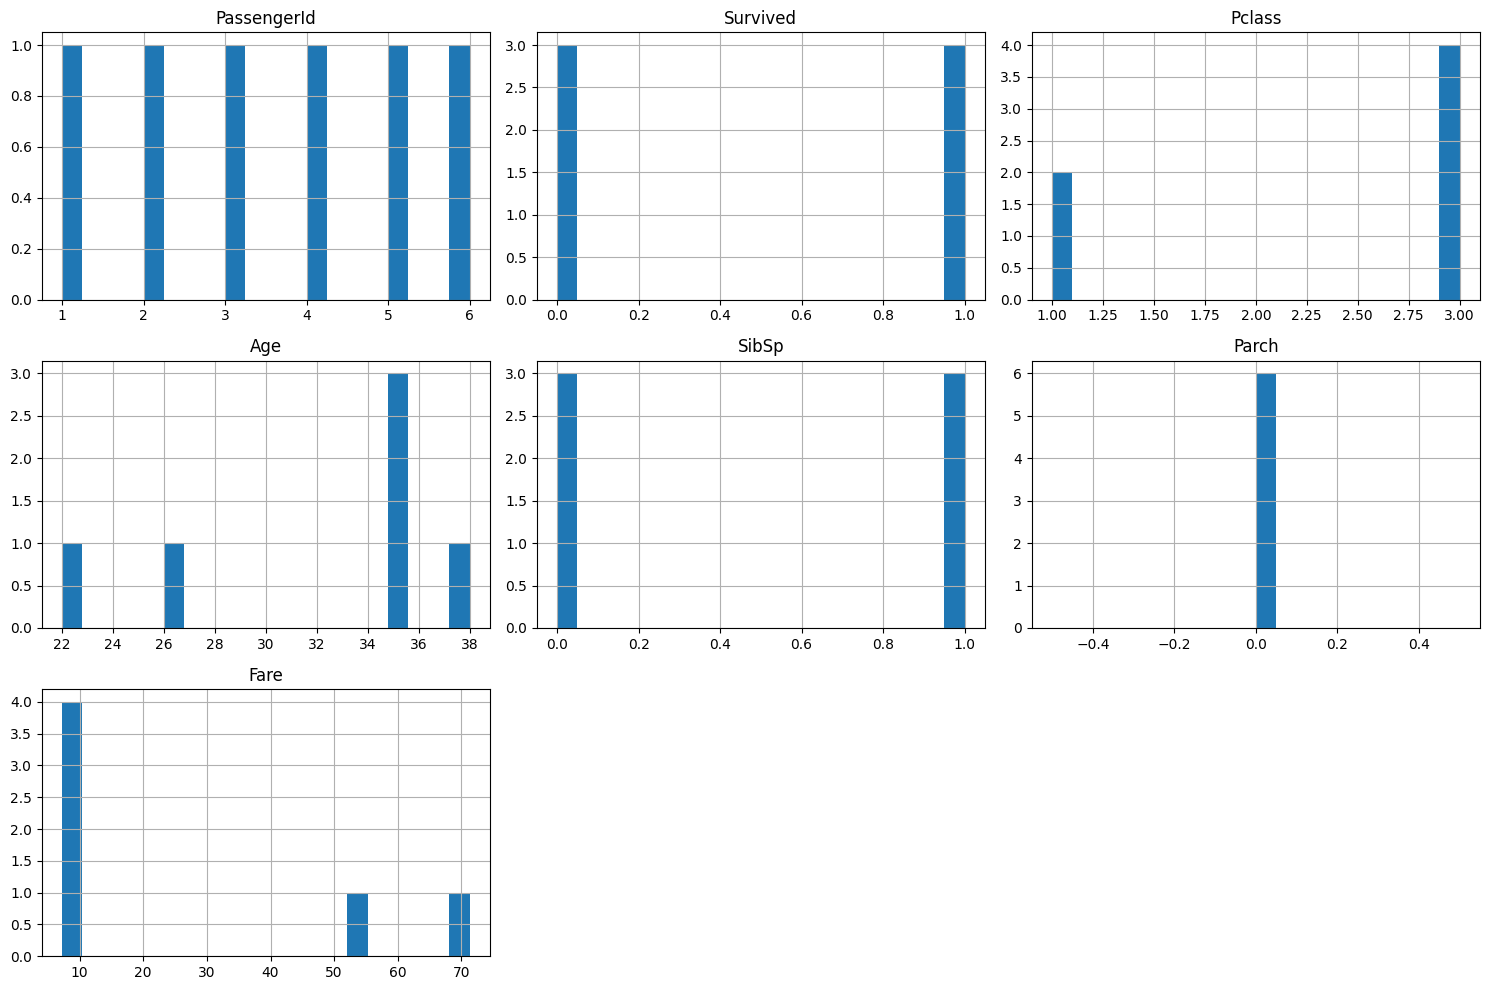

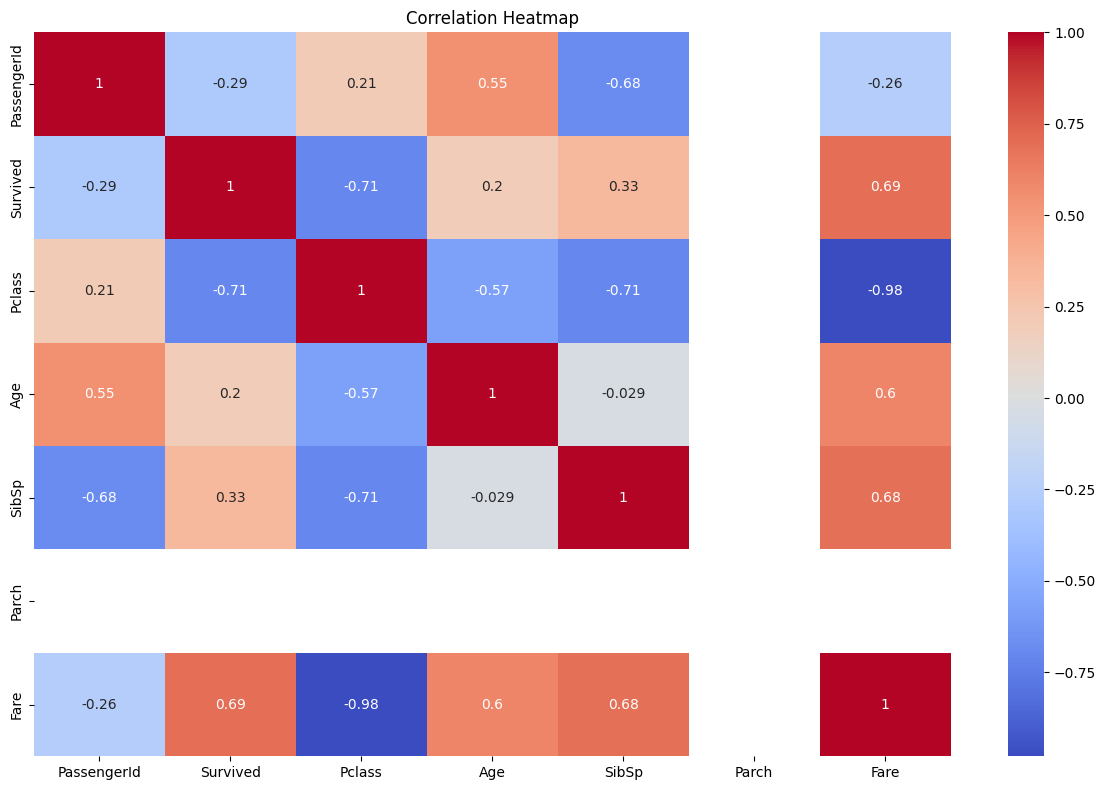

In [15]:
import os

os.makedirs("charts", exist_ok=True)

# Save histogram
df.hist(figsize=(15,10), bins=20)
plt.tight_layout()
plt.savefig("charts/distribution.png")
plt.show()

# Save correlation heatmap
plt.figure(figsize=(12,8))
sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("charts/correlation.png")
plt.show()

In [16]:
df.to_csv("EDA_Analyzed_Dataset.csv", index=False)

from google.colab import files
files.download("EDA_Analyzed_Dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
# Generate EDA Summary Report

report = []

report.append("SWYNEX - EXPLORATORY DATA ANALYSIS")
report.append("=" * 45)

report.append(f"\nTotal Rows: {df.shape[0]}")
report.append(f"Total Columns: {df.shape[1]}")
report.append(f"Missing Values: {df.isnull().sum().sum()}")
report.append(f"Duplicate Rows: {df.duplicated().sum()}")

report.append("\nSTATISTICAL SUMMARY")
report.append(str(df.describe()))

report.append("\nMISSING VALUE ANALYSIS")
report.append(str(df.isnull().sum()))

report.append("\nTOP CATEGORICAL VALUES")

for col in df.select_dtypes(include="object").columns:
    report.append(f"\n{col}")
    report.append(str(df[col].value_counts().head(5)))

with open("EDA_Report.txt", "w") as f:
    f.write("\n".join(report))

print("EDA Report created successfully!")

EDA Report created successfully!


In [18]:
from google.colab import files

files.download("EDA_Report.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
!pip -q install reportlab

from reportlab.lib.pagesizes import A4
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer
from reportlab.lib.styles import getSampleStyleSheet

doc = SimpleDocTemplate("SWYNEX_EDA_Report.pdf")
styles = getSampleStyleSheet()

content = []

content.append(Paragraph(
    "SWYNEX - Exploratory Data Analysis",
    styles["Title"]
))

content.append(Spacer(1, 20))

for line in report:
    content.append(Paragraph(
        line.replace("&", "&amp;").replace("<", "&lt;"),
        styles["Normal"]
    ))
    content.append(Spacer(1, 8))

doc.build(content)

print("PDF Report Created Successfully!")

PDF Report Created Successfully!


In [20]:
files.download("SWYNEX_EDA_Report.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
import zipfile
from google.colab import files

chart_files = [
    "Distribution_Chart.png",
    "Correlation_Heatmap.png",
    "Outlier_Boxplot.png",
    "Average_Bar_Chart.png"
]

with zipfile.ZipFile("SWYNEX_EDA_Charts.zip", "w") as zipf:
    for file in chart_files:
        zipf.write(file)

files.download("SWYNEX_EDA_Charts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>